# ConvNeXt Tiny refinado para Retinopatía Diabética Referible

Pipeline binario orientado a **tamizaje/diagnóstico asistido** de retinopatía diabética referible (RDR).

Mejoras principales respecto al notebook original:

- separación estricta por paciente entre entrenamiento, ajuste, calibración y prueba;
- validación y prueba únicamente con imágenes originales, no con ocho variantes correlacionadas;
- preprocesamiento idéntico en entrenamiento, inferencia y Grad-CAM;
- aumento de datos realmente activo y aplicado en línea;
- cabeza compacta con pooling promedio + máximo para combinar señales difusas y lesiones focales;
- fine-tuning limitado a la última etapa de ConvNeXt con tasa de aprendizaje muy baja;
- calibración de probabilidades mediante temperature scaling;
- selección del umbral clínico en calibración y evaluación final en un conjunto no usado;
- intervalos de confianza bootstrap, TTA y Grad-CAM estabilizado.

> **Importante:** este notebook sirve para investigación y apoyo a la decisión. No sustituye validación externa multicéntrica ni aprobación clínica/regulatoria.

## 1. Instalación y descarga del dataset

Ejecuta las siguientes celdas en Google Colab. Si el dataset y los manifiestos ya están disponibles, puedes omitir la descarga.

In [40]:
##!pip -q install -U kaggle plotly kaleido

In [41]:
""" Cargar kaggle.json únicamente cuando sea necesario.
from google.colab import files
uploaded = files.upload()"""

' Cargar kaggle.json únicamente cuando sea necesario.\nfrom google.colab import files\nuploaded = files.upload()'

In [42]:
import os
import shutil

"""os.makedirs('/root/.kaggle', exist_ok=True)

if 'kaggle.json' not in uploaded:
    raise FileNotFoundError('Selecciona el archivo kaggle.json.')

shutil.copy('kaggle.json', '/root/.kaggle/kaggle.json')
os.chmod('/root/.kaggle/kaggle.json', 0o600)
print('Credenciales de Kaggle configuradas.')"""

"os.makedirs('/root/.kaggle', exist_ok=True)\n\nif 'kaggle.json' not in uploaded:\n    raise FileNotFoundError('Selecciona el archivo kaggle.json.')\n\nshutil.copy('kaggle.json', '/root/.kaggle/kaggle.json')\nos.chmod('/root/.kaggle/kaggle.json', 0o600)\nprint('Credenciales de Kaggle configuradas.')"

In [43]:
DATASET_ID = 'mohamedabdalkader/indian-diabetic-retinopathy-image-dataset-idrid2'
DATA_DIR = '/content/data/IDRiD2'
os.makedirs(DATA_DIR, exist_ok=True)

#!kaggle datasets download -d {DATASET_ID} -p {DATA_DIR} --unzip

## 2. Importaciones y configuración reproducible

In [44]:
import gc
import json
import math
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize_scalar
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, mixed_precision

warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

GPUS = tf.config.list_physical_devices('GPU')
for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

mixed_precision.set_global_policy('mixed_float16' if GPUS else 'float32')

print('TensorFlow:', tf.__version__)
print('GPU:', GPUS)
print('Política:', mixed_precision.global_policy())

TensorFlow: 2.21.0
GPU: []
Política: <DTypePolicy "float32">


In [45]:
# Parámetros principales
CLASS_NAMES = {0: 'No referible', 1: 'Referible'}
MODEL_NAME = 'ConvNeXt_Tiny_Clinical'

IMG_SIZE = (320, 320)
BATCH_SIZE = 16 if GPUS else 8

HEAD_EPOCHS = 20
FINE_TUNE_EPOCHS = 20
HEAD_LR = 2e-4
FINE_TUNE_LR = 3e-6
WEIGHT_DECAY = 1e-4

TARGET_SENSITIVITY = 0.90
UNCERTAINTY_MARGIN = 0.08
USE_TTA = True
BOOTSTRAP_ITERATIONS = 1000

TRAIN_MANIFEST_PATH = Path('C:\\Users\\lauri\\Documents\\PROYECTO_FINAL\\data\\train_split.csv')
HOLDOUT_MANIFEST_PATH = Path('C:\\Users\\lauri\\Documents\\PROYECTO_FINAL\\data\\val_split.csv')
TRAIN_IMAGE_ROOT = Path('C:\\Users\\lauri\\Documents\\PROYECTO_FINAL\\data\\IDRiD2\\IDRiD\\train\\images')
EXTERNAL_IMAGE_ROOT = Path('C:\\Users\\lauri\\Documents\\PROYECTO_FINAL\\data\\IDRiD2\\IDRiD\\test\\images')

RUN_DIR = Path('C:\\Users\\lauri\\Documents\\PROYECTO_FINAL') / MODEL_NAME
CACHE_DIR = RUN_DIR / 'cache'
RUN_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

PHASE1_PATH = RUN_DIR / f'{MODEL_NAME}_phase1.keras'
PHASE2_PATH = RUN_DIR / f'{MODEL_NAME}_phase2.keras'
FINAL_MODEL_PATH = RUN_DIR / f'{MODEL_NAME}_final.keras'
CONFIG_PATH = RUN_DIR / 'clinical_config.json'
METRICS_PATH = RUN_DIR / 'test_metrics.json'
PREDICTIONS_PATH = RUN_DIR / 'test_predictions.csv'
HISTORY_PATH = RUN_DIR / 'training_history.csv'

AUTOTUNE = tf.data.AUTOTUNE

print('Resultados:', RUN_DIR)
print('Imagen:', IMG_SIZE, '| Batch:', BATCH_SIZE)

Resultados: C:\Users\lauri\Documents\PROYECTO_FINAL\ConvNeXt_Tiny_Clinical
Imagen: (320, 320) | Batch: 8


## 3. Partición clínica por paciente

El manifiesto original contiene ocho versiones por paciente. Se utilizan todas las versiones únicamente para el grupo de entrenamiento. Los conjuntos de ajuste, calibración y prueba contienen solo la imagen original de cada paciente.

- **Entrenamiento (75 % del desarrollo):** aprende parámetros.
- **Ajuste:** early stopping y selección entre fase 1/fase 2.
- **Calibración:** temperature scaling y umbral clínico.
- **Prueba:** evaluación final no utilizada durante el desarrollo.

In [46]:
def add_original_flag(df):
    df = df.copy()
    df['Image name'] = df['Image name'].astype(str)
    df['patient_id'] = df['patient_id'].astype(str)
    df['is_original'] = df['Image name'].eq(df['patient_id'])
    return df

train_manifest = add_original_flag(pd.read_csv(TRAIN_MANIFEST_PATH))
holdout_manifest = add_original_flag(pd.read_csv(HOLDOUT_MANIFEST_PATH))

required_columns = {'Image name', 'patient_id', 'binary_label'}
for name, df in {'train': train_manifest, 'holdout': holdout_manifest}.items():
    missing = required_columns.difference(df.columns)
    if missing:
        raise ValueError(f'Faltan columnas en {name}: {sorted(missing)}')

# Una fila original por paciente para crear los grupos.
dev_patients = (
    train_manifest.loc[train_manifest['is_original'], ['patient_id', 'binary_label']]
    .drop_duplicates('patient_id')
    .reset_index(drop=True)
)

# 75 % entrenamiento; 12.5 % ajuste; 12.5 % calibración.
fit_patients, temporary_patients = train_test_split(
    dev_patients,
    test_size=0.25,
    random_state=SEED,
    stratify=dev_patients['binary_label'],
)

tune_patients, calibration_patients = train_test_split(
    temporary_patients,
    test_size=0.50,
    random_state=SEED,
    stratify=temporary_patients['binary_label'],
)

fit_ids = set(fit_patients['patient_id'])
tune_ids = set(tune_patients['patient_id'])
calibration_ids = set(calibration_patients['patient_id'])

fit_df = train_manifest[train_manifest['patient_id'].isin(fit_ids)].copy()
tune_df = train_manifest[
    train_manifest['patient_id'].isin(tune_ids) & train_manifest['is_original']
].copy()
calibration_df = train_manifest[
    train_manifest['patient_id'].isin(calibration_ids) & train_manifest['is_original']
].copy()
test_df = holdout_manifest[holdout_manifest['is_original']].copy()

split_frames = {
    'fit': fit_df,
    'tune': tune_df,
    'calibration': calibration_df,
    'test': test_df,
}

# Auditoría de solapamiento por paciente.
patient_sets = {name: set(df['patient_id']) for name, df in split_frames.items()}
for left_name, left_set in patient_sets.items():
    for right_name, right_set in patient_sets.items():
        if left_name < right_name:
            overlap = left_set.intersection(right_set)
            if overlap:
                raise ValueError(f'Solapamiento {left_name}/{right_name}: {len(overlap)} pacientes')

summary_rows = []
for name, df in split_frames.items():
    summary_rows.append({
        'split': name,
        'images': len(df),
        'patients': df['patient_id'].nunique(),
        'no_referible': int((df['binary_label'] == 0).sum()),
        'referible': int((df['binary_label'] == 1).sum()),
        'original_only': bool(df['is_original'].all()),
    })

split_summary = pd.DataFrame(summary_rows)
display(split_summary)

for name, df in split_frames.items():
    df.to_csv(RUN_DIR / f'{name}_manifest.csv', index=False)

,split,images,patients,no_referible,referible,original_only
0,fit,1976,247,736,1240,False
1,tune,41,41,15,26,True
2,calibration,42,42,16,26,True
3,test,83,83,31,52,True


## 4. Resolución explícita de rutas

Los directorios `train/images` y `test/images` contienen nombres repetidos pero imágenes distintas. Por ello, el desarrollo se resuelve exclusivamente contra `train/images`; nunca se elige una ruta por puntuación entre ambos directorios.

In [47]:
IMAGE_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp')


def resolve_image_path(image_name, root):
    image_name = str(image_name).strip()
    supplied = root / image_name
    if supplied.suffix.lower() in IMAGE_EXTENSIONS and supplied.exists():
        return str(supplied)

    stem = Path(image_name).stem
    for extension in IMAGE_EXTENSIONS:
        candidate = root / f'{stem}{extension}'
        if candidate.exists():
            return str(candidate)
    return None


for name, df in split_frames.items():
    df['image_path'] = df['Image name'].map(lambda value: resolve_image_path(value, TRAIN_IMAGE_ROOT))
    missing = df[df['image_path'].isna()]
    if not missing.empty:
        display(missing[['Image name', 'patient_id']].head(20))
        raise FileNotFoundError(f'No se localizaron {len(missing)} imágenes de {name}.')

# Reasignar variables después de añadir image_path.
fit_df = split_frames['fit']
tune_df = split_frames['tune']
calibration_df = split_frames['calibration']
test_df = split_frames['test']

all_paths = {name: set(df['image_path']) for name, df in split_frames.items()}
for left_name, left_paths in all_paths.items():
    for right_name, right_paths in all_paths.items():
        if left_name < right_name and left_paths.intersection(right_paths):
            raise ValueError(f'Hay archivos compartidos entre {left_name} y {right_name}.')

print('Rutas verificadas sin solapamiento.')
display(fit_df[['Image name', 'patient_id', 'binary_label', 'image_path']].head())

Rutas verificadas sin solapamiento.


,Image name,patient_id,binary_label,image_path
1,IDRiD_002,IDRiD_002,1,C:\Users\lauri\Documents\PROYECTO_FINAL\data\I...
2,IDRiD_004,IDRiD_004,1,C:\Users\lauri\Documents\PROYECTO_FINAL\data\I...
3,IDRiD_005,IDRiD_005,1,C:\Users\lauri\Documents\PROYECTO_FINAL\data\I...
5,IDRiD_007,IDRiD_007,1,C:\Users\lauri\Documents\PROYECTO_FINAL\data\I...
6,IDRiD_008,IDRiD_008,1,C:\Users\lauri\Documents\PROYECTO_FINAL\data\I...


## 5. Preprocesamiento uniforme y aumento de datos

El recorte de bordes negros y el redimensionamiento se usan en todos los modos. El aumento está dentro del modelo, por lo que permanece aleatorio en cada época y queda desactivado automáticamente durante inferencia.

In [48]:
def crop_black_borders(image, threshold=10.0):
    image = tf.cast(image, tf.float32)
    grayscale = tf.reduce_mean(image, axis=-1)
    coordinates = tf.where(grayscale > threshold)

    def crop():
        minimum = tf.reduce_min(coordinates, axis=0)
        maximum = tf.reduce_max(coordinates, axis=0)
        y0 = tf.cast(minimum[0], tf.int32)
        x0 = tf.cast(minimum[1], tf.int32)
        y1 = tf.cast(maximum[0] + 1, tf.int32)
        x1 = tf.cast(maximum[1] + 1, tf.int32)
        return image[y0:y1, x0:x1, :]

    return tf.cond(tf.shape(coordinates)[0] > 0, crop, lambda: image)


def decode_fundus(image_path):
    image_bytes = tf.io.read_file(image_path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = crop_black_borders(image)
    image = tf.image.resize_with_pad(
        image,
        target_height=IMG_SIZE[0],
        target_width=IMG_SIZE[1],
        method='bicubic',
        antialias=True,
    )
    image = tf.clip_by_value(image, 0.0, 255.0)
    return tf.cast(image, tf.uint8)


def decode_with_label(image_path, label):
    return decode_fundus(image_path), tf.cast([label], tf.float32)


def make_dataset(dataframe, training=False, cache_name=None):
    paths = dataframe['image_path'].astype(str).to_numpy()
    labels = dataframe['binary_label'].astype(np.float32).to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(
        decode_with_label,
        num_parallel_calls=AUTOTUNE,
        deterministic=not training,
    )

    # Caché antes del aumento: solo guarda el preprocesamiento determinista.
    if cache_name:
        dataset = dataset.cache(str(CACHE_DIR / cache_name))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)


fit_ds = make_dataset(fit_df, training=True, cache_name='fit')
tune_ds = make_dataset(tune_df, training=False, cache_name='tune')
calibration_ds = make_dataset(calibration_df, training=False, cache_name='calibration')
test_ds = make_dataset(test_df, training=False, cache_name='test')

print(fit_ds.element_spec)

(TensorSpec(shape=(None, 320, 320, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(None, 1), dtype=tf.float32, name=None))


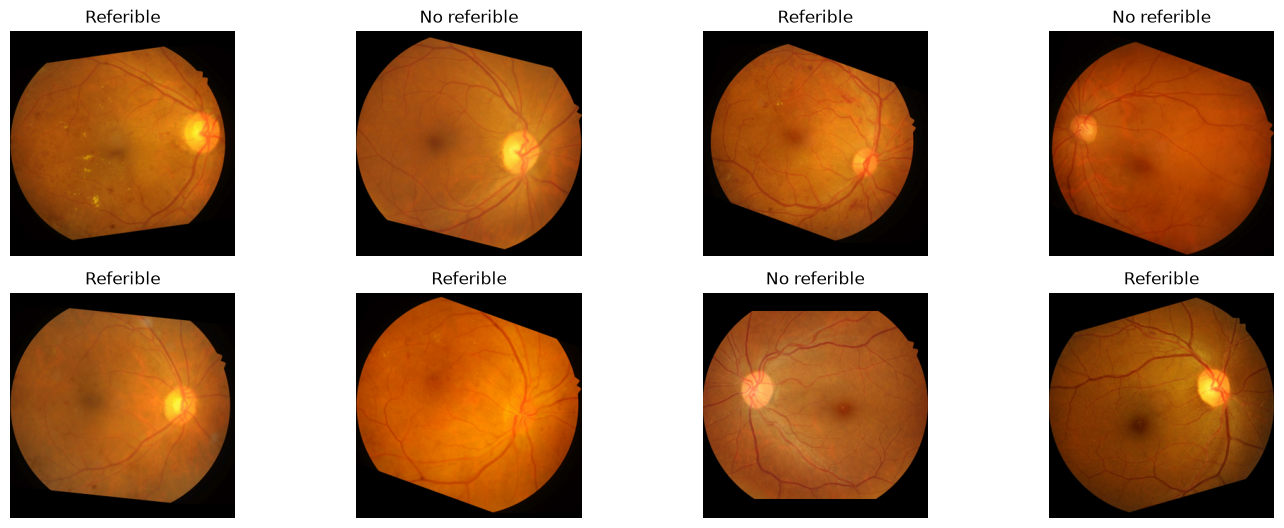

Rango: 0 255


In [49]:
# Revisión visual del lote preprocesado.
batch_images, batch_labels = next(iter(fit_ds.take(1)))

plt.figure(figsize=(14, 8))
for index in range(min(12, len(batch_images))):
    plt.subplot(3, 4, index + 1)
    plt.imshow(batch_images[index].numpy())
    label = int(batch_labels[index, 0].numpy())
    plt.title(CLASS_NAMES[label])
    plt.axis('off')
plt.tight_layout()
plt.show()

print('Rango:', int(tf.reduce_min(batch_images)), int(tf.reduce_max(batch_images)))

## 6. Modelo ConvNeXt Tiny

No se añaden muchas capas densas porque el notebook original ya muestra sobreajuste temprano. La mejora de representación se realiza con **GlobalAveragePooling + GlobalMaxPooling**, útil para combinar distribución global y activaciones focales.

In [50]:
"""data_augmentation = keras.Sequential(
    [
        layers.RandomFlip('horizontal', seed=SEED),
        layers.RandomRotation(0.02, fill_mode='reflect', seed=SEED),
        layers.RandomTranslation(0.02, 0.02, fill_mode='reflect', seed=SEED),
        layers.RandomZoom(
            height_factor=(-0.04, 0.06),
            width_factor=(-0.04, 0.06),
            fill_mode='reflect',
            seed=SEED,
        ),
        layers.RandomContrast(0.12, seed=SEED),
        layers.RandomBrightness(0.06, value_range=(0.0, 255.0), seed=SEED),
    ],
    name='clinical_augmentation',
)


def build_convnext_tiny():
    backbone = tf.keras.applications.ConvNeXtTiny(
        include_top=False,
        include_preprocessing=True,
        weights='imagenet',
        input_shape=(*IMG_SIZE, 3),
        pooling=None,
        name='convnext_tiny',
    )
    backbone.trainable = False

    inputs = keras.Input(shape=(*IMG_SIZE, 3), dtype=tf.uint8, name='fundus_image')
    x = layers.Rescaling(1.0, dtype='float32', name='cast_to_float')(inputs)
    x = data_augmentation(x)
    feature_map = backbone(x)

    average_features = layers.GlobalAveragePooling2D(name='global_average_pool')(feature_map)
    maximum_features = layers.GlobalMaxPooling2D(name='global_max_pool')(feature_map)
    x = layers.Concatenate(name='dual_pool_concat')([average_features, maximum_features])
    x = layers.LayerNormalization(epsilon=1e-6, name='head_layer_norm')(x)
    x = layers.Dropout(0.40, name='head_dropout_1')(x)
    x = layers.Dense(
        256,
        activation=keras.activations.gelu,
        kernel_regularizer=keras.regularizers.l2(1e-4),
        name='clinical_dense',
    )(x)
    x = layers.Dropout(0.30, name='head_dropout_2')(x)

    outputs = layers.Dense(
        1,
        activation='sigmoid',
        dtype='float32',
        name='referable_probability',
    )(x)

    model = keras.Model(inputs, outputs, name='ConvNeXtTiny_RDR_Clinical')
    return model, backbone


def clinical_metrics():
    return [
        keras.metrics.BinaryAccuracy(name='accuracy'),
        keras.metrics.AUC(curve='ROC', num_thresholds=300, name='roc_auc'),
        keras.metrics.AUC(curve='PR', num_thresholds=300, name='pr_auc'),
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
        keras.metrics.SensitivityAtSpecificity(
            specificity=0.80,
            num_thresholds=300,
            name='sens_at_spec80',
        ),
        keras.metrics.SpecificityAtSensitivity(
            sensitivity=TARGET_SENSITIVITY,
            num_thresholds=300,
            name='spec_at_target_sens',
        ),
    ]


def compile_model(model, learning_rate):
    optimizer = keras.optimizers.AdamW(
        learning_rate=learning_rate,
        weight_decay=WEIGHT_DECAY,
        global_clipnorm=1.0,
    )
    model.compile(
        optimizer=optimizer,
        loss=keras.losses.BinaryCrossentropy(),
        metrics=clinical_metrics(),
    )


model, backbone = build_convnext_tiny()
compile_model(model, HEAD_LR)
model.summary()"""

"data_augmentation = keras.Sequential(\n    [\n        layers.RandomFlip('horizontal', seed=SEED),\n        layers.RandomRotation(0.02, fill_mode='reflect', seed=SEED),\n        layers.RandomTranslation(0.02, 0.02, fill_mode='reflect', seed=SEED),\n        layers.RandomZoom(\n            height_factor=(-0.04, 0.06),\n            width_factor=(-0.04, 0.06),\n            fill_mode='reflect',\n            seed=SEED,\n        ),\n        layers.RandomContrast(0.12, seed=SEED),\n        layers.RandomBrightness(0.06, value_range=(0.0, 255.0), seed=SEED),\n    ],\n    name='clinical_augmentation',\n)\n\n\ndef build_convnext_tiny():\n    backbone = tf.keras.applications.ConvNeXtTiny(\n        include_top=False,\n        include_preprocessing=True,\n        weights='imagenet',\n        input_shape=(*IMG_SIZE, 3),\n        pooling=None,\n        name='convnext_tiny',\n    )\n    backbone.trainable = False\n\n    inputs = keras.Input(shape=(*IMG_SIZE, 3), dtype=tf.uint8, name='fundus_image')\n   

In [51]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


# ============================================================
# CONVNEXT-TINY SIN DATA AUGMENTATION
# ============================================================

def build_convnext_tiny():

    # --------------------------------------------------------
    # Backbone preentrenado en ImageNet
    # --------------------------------------------------------
    backbone = tf.keras.applications.ConvNeXtTiny(
        include_top=False,
        include_preprocessing=True,
        weights='imagenet',
        input_shape=(*IMG_SIZE, 3),
        pooling=None,
        name='convnext_tiny',
    )

    # Fase inicial:
    # backbone completamente congelado
    backbone.trainable = False

    # --------------------------------------------------------
    # Entrada
    # --------------------------------------------------------
    inputs = keras.Input(
        shape=(*IMG_SIZE, 3),
        dtype=tf.uint8,
        name='fundus_image',
    )

    # Convierte uint8 -> float32.
    # IMPORTANTE:
    # No divide entre 255 porque ConvNeXtTiny,
    # con include_preprocessing=True,
    # realiza internamente su propio preprocesamiento.
    x = layers.Rescaling(
        scale=1.0,
        dtype='float32',
        name='cast_to_float',
    )(inputs)

    # --------------------------------------------------------
    # NO HAY DATA AUGMENTATION
    # --------------------------------------------------------

    # Extracción de características
    feature_map = backbone(x)

    # --------------------------------------------------------
    # Dual pooling
    # --------------------------------------------------------
    average_features = layers.GlobalAveragePooling2D(
        name='global_average_pool'
    )(feature_map)

    maximum_features = layers.GlobalMaxPooling2D(
        name='global_max_pool'
    )(feature_map)

    x = layers.Concatenate(
        name='dual_pool_concat'
    )([
        average_features,
        maximum_features,
    ])

    # --------------------------------------------------------
    # Cabeza de clasificación
    # --------------------------------------------------------
    x = layers.LayerNormalization(
        epsilon=1e-6,
        name='head_layer_norm',
    )(x)

    x = layers.Dropout(
        0.40,
        name='head_dropout_1',
    )(x)

    x = layers.Dense(
        256,
        activation=keras.activations.gelu,
        kernel_regularizer=keras.regularizers.l2(1e-4),
        name='clinical_dense',
    )(x)

    x = layers.Dropout(
        0.30,
        name='head_dropout_2',
    )(x)

    # --------------------------------------------------------
    # Salida binaria
    # --------------------------------------------------------
    outputs = layers.Dense(
        1,
        activation='sigmoid',
        dtype='float32',
        name='referable_probability',
    )(x)

    model = keras.Model(
        inputs=inputs,
        outputs=outputs,
        name='ConvNeXtTiny_RDR_Clinical',
    )

    return model, backbone


# ============================================================
# MÉTRICAS CLÍNICAS
# ============================================================

def clinical_metrics():
    return [
        keras.metrics.BinaryAccuracy(
            name='accuracy'
        ),

        keras.metrics.AUC(
            curve='ROC',
            num_thresholds=300,
            name='roc_auc',
        ),

        keras.metrics.AUC(
            curve='PR',
            num_thresholds=300,
            name='pr_auc',
        ),

        keras.metrics.Precision(
            name='precision'
        ),

        keras.metrics.Recall(
            name='recall'
        ),

        keras.metrics.SensitivityAtSpecificity(
            specificity=0.80,
            num_thresholds=300,
            name='sens_at_spec80',
        ),

        keras.metrics.SpecificityAtSensitivity(
            sensitivity=TARGET_SENSITIVITY,
            num_thresholds=300,
            name='spec_at_target_sens',
        ),
    ]


# ============================================================
# COMPILACIÓN
# ============================================================

def compile_model(model, learning_rate):

    optimizer = keras.optimizers.AdamW(
        learning_rate=learning_rate,
        weight_decay=WEIGHT_DECAY,
        global_clipnorm=1.0,
    )

    model.compile(
        optimizer=optimizer,
        loss=keras.losses.BinaryCrossentropy(),
        metrics=clinical_metrics(),
    )


# ============================================================
# CONSTRUIR Y COMPILAR
# ============================================================

model, backbone = build_convnext_tiny()

compile_model(
    model=model,
    learning_rate=HEAD_LR,
)

model.summary()

Model: "ConvNeXtTiny_RDR_Clinical"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ fundus_image        │ (None, 320, 320,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cast_to_float       │ (None, 320, 320,  │          0 │ fundus_image[0][… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ convnext_tiny       │ (None, 10, 10,    │ 27,820,128 │ cast_to_float[0]… │
│ (Functional)        │ 768)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_pool │ (None, 768)       │          0 │ convnext_tiny[0]… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pool     │ (None, 768)       │          0 │ convnext_tiny[0]… │
│ (GlobalMaxPooling2… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dual_pool_concat    │ (None, 1536)      │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ global_max_pool[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_layer_norm     │ (None, 1536)      │      3,072 │ dual_pool_concat… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_dropout_1      │ (None, 1536)      │          0 │ head_layer_norm[… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clinical_dense      │ (None, 256)       │    393,472 │ head_dropout_1[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_dropout_2      │ (None, 256)       │          0 │ clinical_dense[0… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ referable_probabil… │ (None, 1)         │        257 │ head_dropout_2[0… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 28,216,929 (107.64 MB)

 Trainable params: 396,801 (1.51 MB)

 Non-trainable params: 27,820,128 (106.13 MB)

## 7. Callbacks y entrenamiento en dos fases

Los máximos de épocas son deliberadamente holgados; `EarlyStopping` evita continuar cuando el conjunto de ajuste deja de mejorar.

In [52]:
def make_callbacks(phase_name, model_path, patience):
    return [
        keras.callbacks.ModelCheckpoint(
            str(model_path),
            monitor='val_pr_auc',
            mode='max',
            save_best_only=True,
            verbose=1,
        ),
        keras.callbacks.EarlyStopping(
            monitor='val_pr_auc',
            mode='max',
            patience=patience,
            min_delta=1e-3,
            restore_best_weights=True,
            verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            mode='min',
            factor=0.35,
            patience=2,
            min_lr=2e-7,
            verbose=1,
        ),
        keras.callbacks.CSVLogger(str(RUN_DIR / f'{phase_name}_log.csv')),
        keras.callbacks.TerminateOnNaN(),
    ]

In [53]:
# Fase 1: entrenar únicamente la cabeza.
history_head = model.fit(
    fit_ds,
    validation_data=tune_ds,
    epochs=HEAD_EPOCHS,
    callbacks=make_callbacks('phase1', PHASE1_PATH, patience=5),
    verbose=1,
)

Epoch 1/20
247/247 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7060 - loss: 0.6324 - pr_auc: 0.8520 - precision: 0.7457 - recall: 0.8065 - roc_auc: 0.7670 - sens_at_spec80: 0.5718 - spec_at_target_sens: 0.3492
Epoch 1: val_pr_auc improved from None to 0.91630, saving model to C:\Users\lauri\Documents\PROYECTO_FINAL\ConvNeXt_Tiny_Clinical\ConvNeXt_Tiny_Clinical_phase1.keras

Epoch 1: finished saving model to C:\Users\lauri\Documents\PROYECTO_FINAL\ConvNeXt_Tiny_Clinical\ConvNeXt_Tiny_Clinical_phase1.keras
247/247 ━━━━━━━━━━━━━━━━━━━━ 670s 3s/step - accuracy: 0.7060 - loss: 0.6324 - pr_auc: 0.8520 - precision: 0.7457 - recall: 0.8065 - roc_auc: 0.7670 - sens_at_spec80: 0.5718 - spec_at_target_sens: 0.3492 - val_accuracy: 0.8049 - val_loss: 0.5061 - val_pr_auc: 0.9163 - val_precision: 0.7812 - val_recall: 0.9615 - val_roc_auc: 0.8846 - val_sens_at_spec80: 0.8077 - val_spec_at_target_sens: 0.7333 - learning_rate: 2.0000e-04
Epoch 2/20
247/247 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0

In [54]:
# Fase 2: ajustar únicamente la última etapa de ConvNeXt.
model = keras.models.load_model(PHASE1_PATH)
backbone = model.get_layer('convnext_tiny')
backbone.trainable = True

stage3_index = next(
    (index for index, layer in enumerate(backbone.layers) if 'stage_3' in layer.name),
    max(0, len(backbone.layers) - 30),
)

for index, layer in enumerate(backbone.layers):
    layer.trainable = index >= stage3_index

trainable_backbone_layers = sum(layer.trainable for layer in backbone.layers)
print('Capas del backbone:', len(backbone.layers))
print('Capas ajustables:', trainable_backbone_layers)

compile_model(model, FINE_TUNE_LR)

history_fine = model.fit(
    fit_ds,
    validation_data=tune_ds,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=make_callbacks('phase2', PHASE2_PATH, patience=4),
    verbose=1,
)

Capas del backbone: 133
Capas ajustables: 22
Epoch 1/20
247/247 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8856 - loss: 0.3130 - pr_auc: 0.9747 - precision: 0.9149 - recall: 0.9016 - roc_auc: 0.9554 - sens_at_spec80: 0.9298 - spec_at_target_sens: 0.8587
Epoch 1: val_pr_auc improved from None to 0.95242, saving model to C:\Users\lauri\Documents\PROYECTO_FINAL\ConvNeXt_Tiny_Clinical\ConvNeXt_Tiny_Clinical_phase2.keras

Epoch 1: finished saving model to C:\Users\lauri\Documents\PROYECTO_FINAL\ConvNeXt_Tiny_Clinical\ConvNeXt_Tiny_Clinical_phase2.keras
247/247 ━━━━━━━━━━━━━━━━━━━━ 785s 3s/step - accuracy: 0.8856 - loss: 0.3130 - pr_auc: 0.9747 - precision: 0.9149 - recall: 0.9016 - roc_auc: 0.9554 - sens_at_spec80: 0.9298 - spec_at_target_sens: 0.8587 - val_accuracy: 0.8293 - val_loss: 0.5034 - val_pr_auc: 0.9524 - val_precision: 0.8065 - val_recall: 0.9615 - val_roc_auc: 0.9256 - val_sens_at_spec80: 0.9615 - val_spec_at_target_sens: 0.8000 - learning_rate: 3.0000e-06
Epoch 2/20
247/247 

In [55]:
# Selección del mejor candidato usando exclusivamente el conjunto de ajuste.
candidate_rows = []
for path in [PHASE1_PATH, PHASE2_PATH]:
    candidate = keras.models.load_model(path)
    scores = candidate.evaluate(tune_ds, return_dict=True, verbose=0)
    candidate_rows.append({'model_path': str(path), **{k: float(v) for k, v in scores.items()}})
    del candidate
    gc.collect()

candidate_df = pd.DataFrame(candidate_rows).sort_values(
    ['pr_auc', 'roc_auc', 'loss'],
    ascending=[False, False, True],
)
display(candidate_df)

best_path = Path(candidate_df.iloc[0]['model_path'])
model = keras.models.load_model(best_path)
model.save(FINAL_MODEL_PATH, overwrite=True)
print('Modelo final:', FINAL_MODEL_PATH)

,model_path,accuracy,loss,pr_auc,precision,recall,roc_auc,sens_at_spec80,spec_at_target_sens
1,C:\Users\lauri\Documents\PROYECTO_FINAL\ConvNe...,0.853659,0.484918,0.962826,0.833333,0.961538,0.938462,0.961538,0.8
0,C:\Users\lauri\Documents\PROYECTO_FINAL\ConvNe...,0.853659,0.452968,0.935613,0.833333,0.961538,0.908974,0.961538,0.8


Modelo final: C:\Users\lauri\Documents\PROYECTO_FINAL\ConvNeXt_Tiny_Clinical\ConvNeXt_Tiny_Clinical_final.keras


In [56]:
# Historial consolidado.
def history_to_frame(history, phase):
    frame = pd.DataFrame(history.history)
    frame['phase'] = phase
    return frame

history_df = pd.concat(
    [history_to_frame(history_head, 'Cabeza'), history_to_frame(history_fine, 'Fine-tuning')],
    ignore_index=True,
)
history_df.insert(0, 'epoch', np.arange(1, len(history_df) + 1))
history_df.to_csv(HISTORY_PATH, index=False)


18


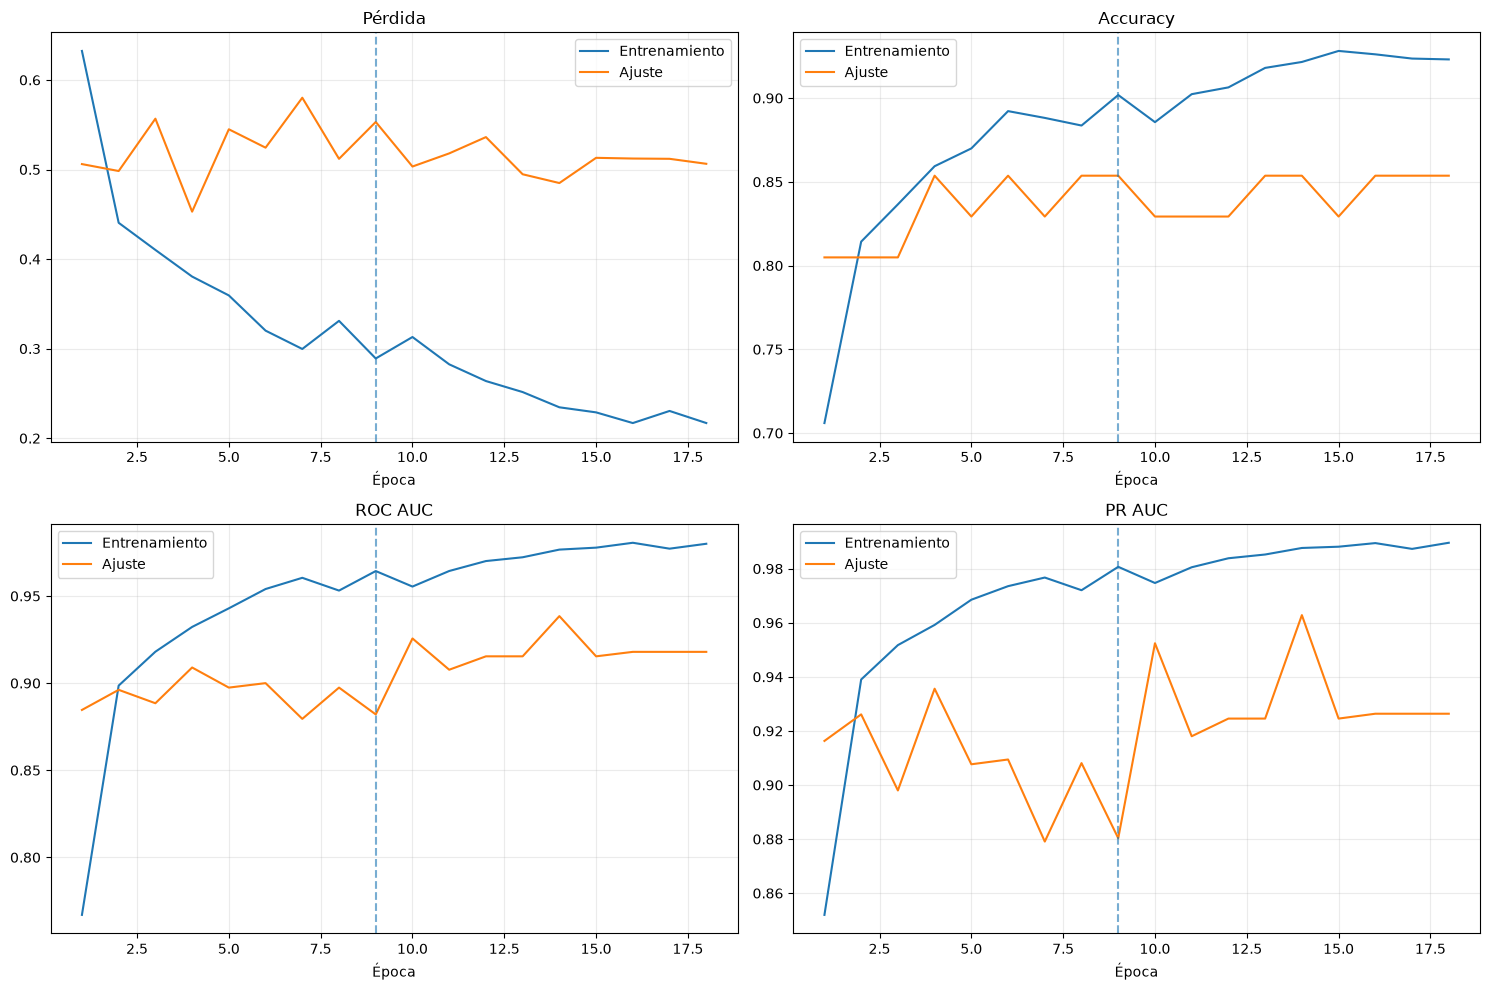

,registro,epoch,accuracy,loss,pr_auc,precision,recall,roc_auc,sens_at_spec80,spec_at_target_sens,val_accuracy,val_loss,val_pr_auc,val_precision,val_recall,val_roc_auc,val_sens_at_spec80,val_spec_at_target_sens,learning_rate,phase
0,1,1,0.705972,0.632407,0.851964,0.745712,0.806452,0.766988,0.571774,0.349185,0.804878,0.506079,0.916302,0.781250,0.961538,0.884615,0.807692,0.733333,2.000000e-04,Cabeza
1,2,2,0.814271,0.440548,0.939016,0.844515,0.862903,0.898585,0.832258,0.653533,0.804878,0.498337,0.926120,0.781250,0.961538,0.896154,0.884615,0.733333,2.000000e-04,Cabeza
2,3,3,0.836538,0.410245,0.951735,0.862451,0.879839,0.918036,0.862097,0.709239,0.804878,0.556781,0.897983,0.781250,0.961538,0.888462,0.884615,0.733333,2.000000e-04,Cabeza
3,4,4,0.859312,0.380504,0.959201,0.886656,0.889516,0.932253,0.892742,0.778533,0.853659,0.452968,0.935613,0.833333,0.961538,0.908974,0.961538,0.800000,2.000000e-04,Cabeza
4,5,5,0.869939,0.359451,0.968523,0.899919,0.891935,0.942934,0.909677,0.813859,0.829268,0.544939,0.907667,0.806452,0.961538,0.897436,0.923077,0.800000,2.000000e-04,Cabeza
5,6,6,0.892206,0.320131,0.973535,0.916464,0.911290,0.954013,0.935484,0.880435,0.853659,0.524418,0.909432,0.833333,0.961538,0.900000,0.923077,0.866667,2.000000e-04,Cabeza
6,7,7,0.888158,0.299668,0.976721,0.909895,0.912097,0.960450,0.936290,0.881793,0.829268,0.580168,0.879084,0.806452,0.961538,0.879487,0.884615,0.733333,6.999999e-05,Cabeza
7,8,8,0.883603,0.331062,0.972035,0.905949,0.908871,0.953119,0.932258,0.853261,0.853659,0.511945,0.908095,0.833333,0.961538,0.897436,0.923077,0.800000,6.999999e-05,Cabeza
8,9,9,0.901822,0.289064,0.980685,0.918400,0.925806,0.964327,0.944355,0.899457,0.853659,0.553118,0.880325,0.833333,0.961538,0.882051,0.923077,0.800000,2.450000e-05,Cabeza
9,10,10,0.885628,0.313012,0.974705,0.914894,0.901613,0.955425,0.929839,0.858696,0.829268,0.503359,0.952419,0.806452,0.961538,0.925641,0.961538,0.800000,3.000000e-06,Fine-tuning


In [57]:
#Leer el archivo csv creado /content/ConvNeXt_Tiny_Clinical/training_history.csv
dfHistoria = pd.read_csv(HISTORY_PATH)

#Agregar una columna de autonumeracion de registros
dfHistoria.insert(0, 'registro', range(1, len(dfHistoria) + 1))


phase_boundary = len(dfHistoria['loss'])
print(phase_boundary)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for axis, metric, title in [
    (axes[0, 0], 'loss', 'Pérdida'),
    (axes[0, 1], 'accuracy', 'Accuracy'),
    (axes[1, 0], 'roc_auc', 'ROC AUC'),
    (axes[1, 1], 'pr_auc', 'PR AUC'),
]:
    axis.plot(dfHistoria['registro'], dfHistoria[metric], label='Entrenamiento')
    axis.plot(dfHistoria['registro'], dfHistoria[f'val_{metric}'], label='Ajuste')
    axis.axvline(phase_boundary //2 , linestyle='--', alpha=0.6)
    axis.set_title(title)
    axis.set_xlabel('Época')
    axis.grid(alpha=0.25)
    axis.legend()
plt.tight_layout()
plt.show()


dfHistoria



## 8. Predicción con TTA y calibración de probabilidad

La TTA promedia la imagen original y su reflejo horizontal. `Temperature scaling` modifica la confianza, no el orden de las predicciones.

In [58]:
def make_image_dataset(dataframe, flip=False):
    paths = dataframe['image_path'].astype(str).to_numpy()
    dataset = tf.data.Dataset.from_tensor_slices(paths)
    dataset = dataset.map(decode_fundus, num_parallel_calls=AUTOTUNE)
    if flip:
        dataset = dataset.map(tf.image.flip_left_right, num_parallel_calls=AUTOTUNE)
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)


def predict_raw(model, dataframe, use_tta=True):
    probabilities = model.predict(make_image_dataset(dataframe, flip=False), verbose=0).reshape(-1)
    if use_tta:
        flipped = model.predict(make_image_dataset(dataframe, flip=True), verbose=0).reshape(-1)
        probabilities = 0.5 * (probabilities + flipped)
    return np.clip(probabilities.astype(np.float64), 1e-6, 1.0 - 1e-6)


def probability_to_logit(probabilities):
    probabilities = np.clip(probabilities, 1e-6, 1.0 - 1e-6)
    return np.log(probabilities / (1.0 - probabilities))


def apply_temperature(probabilities, temperature):
    logits = probability_to_logit(probabilities) / float(temperature)
    return 1.0 / (1.0 + np.exp(-logits))


model = keras.models.load_model(FINAL_MODEL_PATH)
y_calibration = calibration_df['binary_label'].astype(int).to_numpy()
p_calibration_raw = predict_raw(model, calibration_df, use_tta=USE_TTA)


def calibration_nll(temperature):
    calibrated = apply_temperature(p_calibration_raw, temperature)
    return -np.mean(
        y_calibration * np.log(calibrated + 1e-8)
        + (1 - y_calibration) * np.log(1 - calibrated + 1e-8)
    )

result = minimize_scalar(calibration_nll, bounds=(0.25, 8.0), method='bounded')
TEMPERATURE = float(result.x)
p_calibration = apply_temperature(p_calibration_raw, TEMPERATURE)

print('Temperatura:', round(TEMPERATURE, 4))
print('Brier antes:', round(brier_score_loss(y_calibration, p_calibration_raw), 4))
print('Brier después:', round(brier_score_loss(y_calibration, p_calibration), 4))

Temperatura: 2.1648
Brier antes: 0.1229
Brier después: 0.1019


## 9. Selección del umbral clínico

Se selecciona en calibración el umbral con mayor especificidad que conserva la sensibilidad objetivo. La prueba permanece intacta.

In [59]:
def safe_divide(numerator, denominator):
    return float(numerator / denominator) if denominator else 0.0


def threshold_table(y_true, probabilities):
    candidate_thresholds = np.unique(
        np.concatenate([np.linspace(0.0, 1.0, 1001), probabilities])
    )
    rows = []
    for threshold in candidate_thresholds:
        prediction = (probabilities >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, prediction, labels=[0, 1]).ravel()
        sensitivity = safe_divide(tp, tp + fn)
        specificity = safe_divide(tn, tn + fp)
        ppv = safe_divide(tp, tp + fp)
        npv = safe_divide(tn, tn + fn)
        rows.append({
            'threshold': float(threshold),
            'sensitivity': sensitivity,
            'specificity': specificity,
            'ppv': ppv,
            'npv': npv,
            'youden_j': sensitivity + specificity - 1.0,
        })
    return pd.DataFrame(rows)


calibration_thresholds = threshold_table(y_calibration, p_calibration)
eligible = calibration_thresholds[
    calibration_thresholds['sensitivity'] >= TARGET_SENSITIVITY
]

if not eligible.empty:
    selected = eligible.sort_values(
        ['specificity', 'sensitivity', 'npv', 'threshold'],
        ascending=[False, False, False, False],
    ).iloc[0]
    THRESHOLD_METHOD = f'Máxima especificidad con sensibilidad >= {TARGET_SENSITIVITY:.2f}'
else:
    selected = calibration_thresholds.sort_values('youden_j', ascending=False).iloc[0]
    THRESHOLD_METHOD = 'Índice de Youden'

CLINICAL_THRESHOLD = float(selected['threshold'])
print('Método:', THRESHOLD_METHOD)
print(selected[['threshold', 'sensitivity', 'specificity', 'ppv', 'npv']])

Método: Máxima especificidad con sensibilidad >= 0.90
threshold      0.378528
sensitivity    0.923077
specificity    0.812500
ppv            0.888889
npv            0.866667
Name: 394, dtype: float64


## 10. Evaluación final sobre pacientes no utilizados

In [60]:
def calculate_metrics(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    return {
        'threshold': float(threshold),
        'accuracy': float(accuracy_score(y_true, predictions)),
        'balanced_accuracy': float(balanced_accuracy_score(y_true, predictions)),
        'precision_ppv': float(precision_score(y_true, predictions, zero_division=0)),
        'sensitivity': safe_divide(tp, tp + fn),
        'specificity': safe_divide(tn, tn + fp),
        'npv': safe_divide(tn, tn + fn),
        'f1_score': float(f1_score(y_true, predictions, zero_division=0)),
        'roc_auc': float(roc_auc_score(y_true, probabilities)),
        'pr_auc': float(average_precision_score(y_true, probabilities)),
        'brier_score': float(brier_score_loss(y_true, probabilities)),
        'tn': int(tn),
        'fp': int(fp),
        'fn': int(fn),
        'tp': int(tp),
    }


def bootstrap_confidence_intervals(y_true, probabilities, threshold, iterations=1000):
    rng = np.random.default_rng(SEED)
    n = len(y_true)
    metric_names = ['sensitivity', 'specificity', 'roc_auc', 'pr_auc', 'balanced_accuracy']
    samples = {name: [] for name in metric_names}

    for _ in range(iterations):
        indices = rng.integers(0, n, n)
        sampled_y = y_true[indices]
        sampled_p = probabilities[indices]
        if len(np.unique(sampled_y)) < 2:
            continue
        values = calculate_metrics(sampled_y, sampled_p, threshold)
        for name in metric_names:
            samples[name].append(values[name])

    return {
        name: {
            'lower_95': float(np.percentile(values, 2.5)),
            'upper_95': float(np.percentile(values, 97.5)),
        }
        for name, values in samples.items()
        if values
    }


y_test = test_df['binary_label'].astype(int).to_numpy()
p_test_raw = predict_raw(model, test_df, use_tta=USE_TTA)
p_test = apply_temperature(p_test_raw, TEMPERATURE)
y_test_pred = (p_test >= CLINICAL_THRESHOLD).astype(int)

metrics_test = calculate_metrics(y_test, p_test, CLINICAL_THRESHOLD)
confidence_intervals = bootstrap_confidence_intervals(
    y_test,
    p_test,
    CLINICAL_THRESHOLD,
    iterations=BOOTSTRAP_ITERATIONS,
)

display(pd.DataFrame([metrics_test]).T.rename(columns={0: 'valor'}))
print('\nIntervalos de confianza bootstrap 95 %:')
display(pd.DataFrame(confidence_intervals).T)
print('\n', classification_report(
    y_test,
    y_test_pred,
    target_names=[CLASS_NAMES[0], CLASS_NAMES[1]],
    digits=4,
    zero_division=0,
))


,valor
threshold,0.378528
accuracy,0.879518
balanced_accuracy,0.838710
precision_ppv,0.838710
sensitivity,1.000000
specificity,0.677419
npv,1.000000
f1_score,0.912281
roc_auc,0.986973
pr_auc,0.992863



Intervalos de confianza bootstrap 95 %:


,lower_95,upper_95
sensitivity,1.000000,1.000000
specificity,0.500000,0.827586
roc_auc,0.968281,0.999380
pr_auc,0.981520,0.999637
balanced_accuracy,0.750000,0.913793



               precision    recall  f1-score   support

No referible     1.0000    0.6774    0.8077        31
   Referible     0.8387    1.0000    0.9123        52

    accuracy                         0.8795        83
   macro avg     0.9194    0.8387    0.8600        83
weighted avg     0.8990    0.8795    0.8732        83



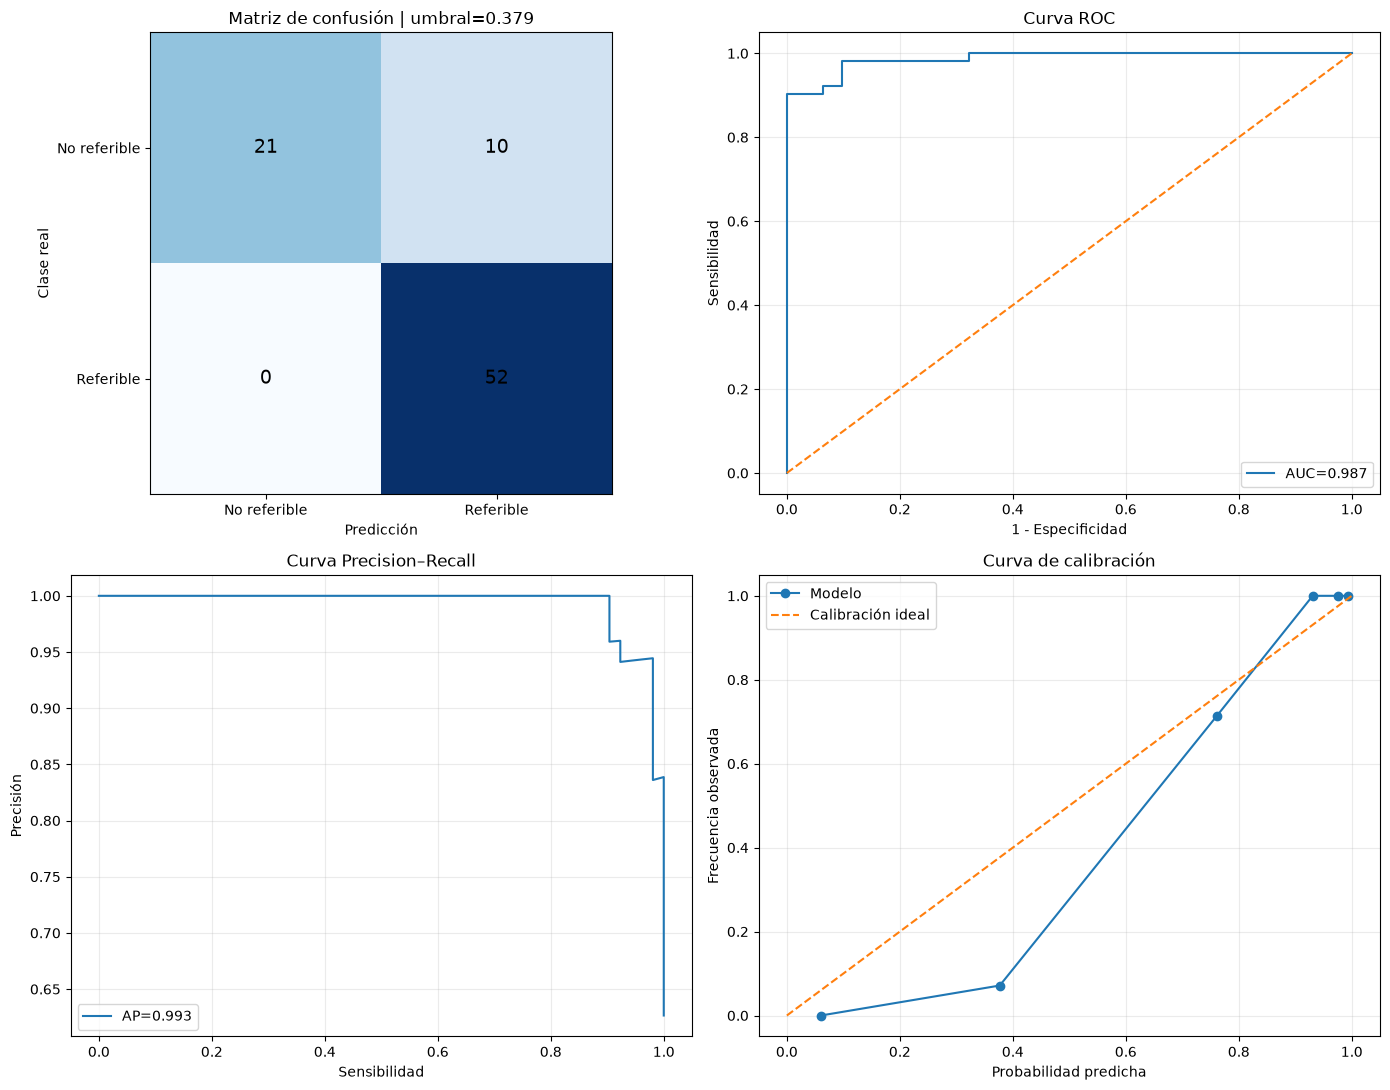

In [61]:
# Matriz de confusión, ROC, PR y calibración.
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])
fpr, tpr, _ = roc_curve(y_test, p_test)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, p_test)
fraction_positive, mean_predicted = calibration_curve(y_test, p_test, n_bins=6, strategy='quantile')

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

axes[0, 0].imshow(cm, cmap='Blues')
for row in range(2):
    for column in range(2):
        axes[0, 0].text(column, row, cm[row, column], ha='center', va='center', fontsize=14)
axes[0, 0].set_xticks([0, 1], [CLASS_NAMES[0], CLASS_NAMES[1]])
axes[0, 0].set_yticks([0, 1], [CLASS_NAMES[0], CLASS_NAMES[1]])
axes[0, 0].set_xlabel('Predicción')
axes[0, 0].set_ylabel('Clase real')
axes[0, 0].set_title(f'Matriz de confusión | umbral={CLINICAL_THRESHOLD:.3f}')

axes[0, 1].plot(fpr, tpr, label=f"AUC={metrics_test['roc_auc']:.3f}")
axes[0, 1].plot([0, 1], [0, 1], linestyle='--')
axes[0, 1].set_xlabel('1 - Especificidad')
axes[0, 1].set_ylabel('Sensibilidad')
axes[0, 1].set_title('Curva ROC')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.25)

axes[1, 0].plot(recall_curve, precision_curve, label=f"AP={metrics_test['pr_auc']:.3f}")
axes[1, 0].set_xlabel('Sensibilidad')
axes[1, 0].set_ylabel('Precisión')
axes[1, 0].set_title('Curva Precision–Recall')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.25)

axes[1, 1].plot(mean_predicted, fraction_positive, marker='o', label='Modelo')
axes[1, 1].plot([0, 1], [0, 1], linestyle='--', label='Calibración ideal')
axes[1, 1].set_xlabel('Probabilidad predicha')
axes[1, 1].set_ylabel('Frecuencia observada')
axes[1, 1].set_title('Curva de calibración')
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

## 11. Guardar modelo, calibración, umbral y predicciones

In [62]:
test_predictions_df = test_df[
    ['Image name', 'patient_id', 'binary_label', 'image_path']
].copy()
test_predictions_df['raw_probability'] = p_test_raw
test_predictions_df['calibrated_probability'] = p_test
test_predictions_df['predicted_label'] = y_test_pred
test_predictions_df['predicted_class'] = test_predictions_df['predicted_label'].map(CLASS_NAMES)
test_predictions_df['correct'] = test_predictions_df['binary_label'].eq(test_predictions_df['predicted_label'])
test_predictions_df['manual_review'] = (
    np.abs(test_predictions_df['calibrated_probability'] - CLINICAL_THRESHOLD)
    <= UNCERTAINTY_MARGIN
)
test_predictions_df.to_csv(PREDICTIONS_PATH, index=False)

clinical_config = {
    'model_name': MODEL_NAME,
    'image_size': list(IMG_SIZE),
    'class_names': CLASS_NAMES,
    'temperature': TEMPERATURE,
    'clinical_threshold': CLINICAL_THRESHOLD,
    'threshold_method': THRESHOLD_METHOD,
    'target_sensitivity': TARGET_SENSITIVITY,
    'uncertainty_margin': UNCERTAINTY_MARGIN,
    'tta_horizontal_flip': USE_TTA,
    'preprocessing': 'crop_black_borders + resize_with_pad + ConvNeXt internal normalization',
}

with open(CONFIG_PATH, 'w', encoding='utf-8') as file:
    json.dump(clinical_config, file, indent=2, ensure_ascii=False)

with open(METRICS_PATH, 'w', encoding='utf-8') as file:
    json.dump(
        {'metrics': metrics_test, 'confidence_intervals_95': confidence_intervals},
        file,
        indent=2,
        ensure_ascii=False,
    )

print('Modelo:', FINAL_MODEL_PATH)
print('Configuración:', CONFIG_PATH)
print('Métricas:', METRICS_PATH)
print('Predicciones:', PREDICTIONS_PATH)

Modelo: C:\Users\lauri\Documents\PROYECTO_FINAL\ConvNeXt_Tiny_Clinical\ConvNeXt_Tiny_Clinical_final.keras
Configuración: C:\Users\lauri\Documents\PROYECTO_FINAL\ConvNeXt_Tiny_Clinical\clinical_config.json
Métricas: C:\Users\lauri\Documents\PROYECTO_FINAL\ConvNeXt_Tiny_Clinical\test_metrics.json
Predicciones: C:\Users\lauri\Documents\PROYECTO_FINAL\ConvNeXt_Tiny_Clinical\test_predictions.csv


## 12. Cargar el modelo sin volver a entrenar

Después de guardar o volver a subir la carpeta de resultados, ejecuta esta celda y continúa desde inferencia.

In [63]:
loaded_model = keras.models.load_model(FINAL_MODEL_PATH)
with open(CONFIG_PATH, 'r', encoding='utf-8') as file:
    loaded_config = json.load(file)

LOADED_TEMPERATURE = float(loaded_config['temperature'])
LOADED_THRESHOLD = float(loaded_config['clinical_threshold'])
LOADED_MARGIN = float(loaded_config['uncertainty_margin'])

print('Modelo y configuración cargados.')
print('Umbral:', LOADED_THRESHOLD, '| Temperatura:', LOADED_TEMPERATURE)

Modelo y configuración cargados.
Umbral: 0.37852828387458237 | Temperatura: 2.164819697330949


## 13. Inferencia externa coherente

Esta sección utiliza exactamente el mismo recorte, redimensionamiento, TTA y calibración. Las imágenes cercanas al umbral se marcan para revisión manual.

In [64]:
def collect_images(path):
    path = Path(path)
    if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
        return [path]
    if not path.exists():
        return []
    return sorted(
        item for item in path.rglob('*')
        if item.is_file() and item.suffix.lower() in IMAGE_EXTENSIONS
    )


def predict_external(image_paths, model=loaded_model):
    external_df = pd.DataFrame({'image_path': [str(path) for path in image_paths]})
    if external_df.empty:
        return external_df

    raw = predict_raw(model, external_df, use_tta=USE_TTA)
    calibrated = apply_temperature(raw, LOADED_TEMPERATURE)
    labels = (calibrated >= LOADED_THRESHOLD).astype(int)
    manual_review = np.abs(calibrated - LOADED_THRESHOLD) <= LOADED_MARGIN

    external_df['image'] = external_df['image_path'].map(lambda value: Path(value).name)
    external_df['raw_probability'] = raw
    external_df['calibrated_probability'] = calibrated
    external_df['predicted_label'] = labels
    external_df['predicted_class'] = [CLASS_NAMES[int(label)] for label in labels]
    external_df['manual_review'] = manual_review
    external_df['clinical_output'] = np.where(
        manual_review,
        'Revisión manual',
        external_df['predicted_class'],
    )
    return external_df


external_paths = collect_images(EXTERNAL_IMAGE_ROOT)
external_predictions_df = predict_external(external_paths[:20])
display(external_predictions_df)

,image_path,image,raw_probability,calibrated_probability,predicted_label,predicted_class,manual_review,clinical_output
0,C:\Users\lauri\Documents\PROYECTO_FINAL\data\I...,IDRiD_001.jpg,0.999930,0.988075,1,Referible,False,Referible
1,C:\Users\lauri\Documents\PROYECTO_FINAL\data\I...,IDRiD_001_L14.jpg,0.999828,0.982074,1,Referible,False,Referible
2,C:\Users\lauri\Documents\PROYECTO_FINAL\data\I...,IDRiD_001_L20.jpg,0.999956,0.990353,1,Referible,False,Referible
3,C:\Users\lauri\Documents\PROYECTO_FINAL\data\I...,IDRiD_001_L6.jpg,0.999955,0.990246,1,Referible,False,Referible
4,C:\Users\lauri\Documents\PROYECTO_FINAL\data\I...,IDRiD_001_R16.jpg,0.999939,0.988792,1,Referible,False,Referible
5,C:\Users\lauri\Documents\PROYECTO_FINAL\data\I...,IDRiD_001_R22.jpg,0.999938,0.988718,1,Referible,False,Referible
6,C:\Users\lauri\Documents\PROYECTO_FINAL\data\I...,IDRiD_001_R8.jpg,0.999894,0.985616,1,Referible,False,Referible
7,C:\Users\lauri\Documents\PROYECTO_FINAL\data\I...,IDRiD_001_VFLIP.jpg,0.999843,0.982816,1,Referible,False,Referible
8,C:\Users\lauri\Documents\PROYECTO_FINAL\data\I...,IDRiD_002.jpg,0.897344,0.731353,1,Referible,False,Referible
9,C:\Users\lauri\Documents\PROYECTO_FINAL\data\I...,IDRiD_002_L14.jpg,0.761136,0.630728,1,Referible,False,Referible


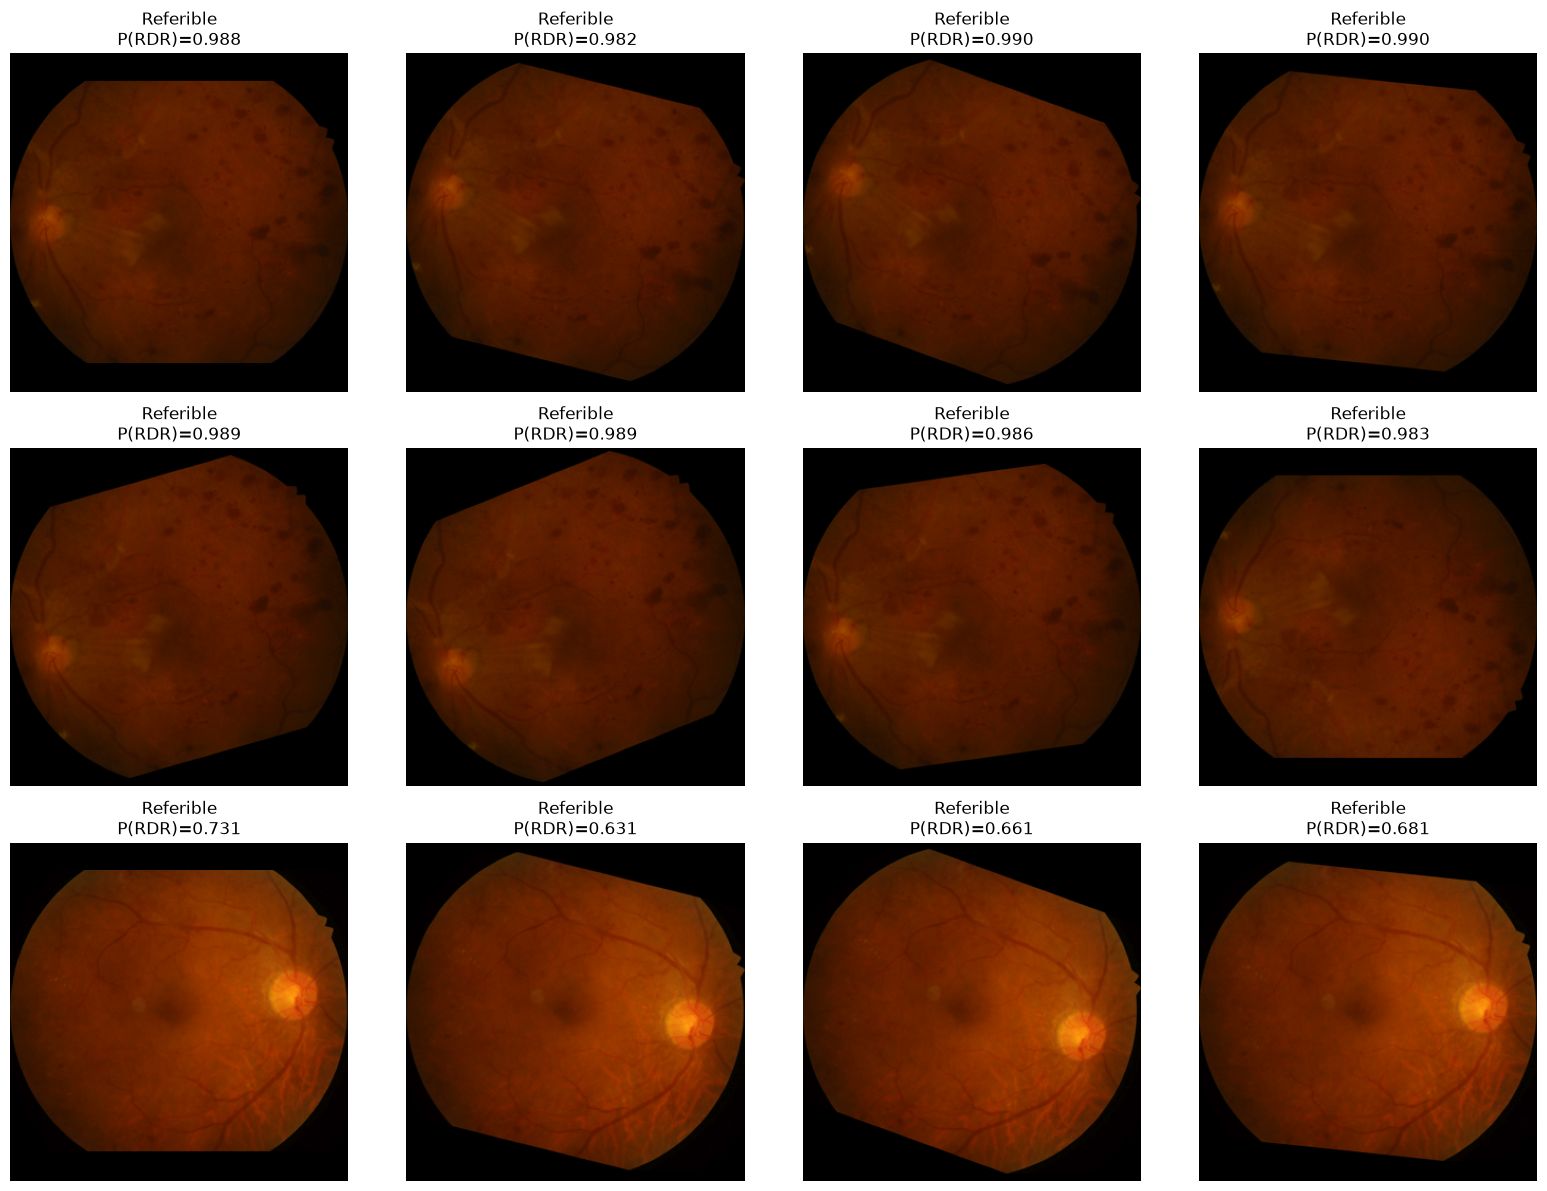

In [65]:
if not external_predictions_df.empty:
    rows = math.ceil(min(12, len(external_predictions_df)) / 4)
    plt.figure(figsize=(16, 4 * rows))
    for index, row in external_predictions_df.head(12).iterrows():
        plt.subplot(rows, 4, index + 1)
        image = decode_fundus(tf.constant(row['image_path'])).numpy()
        plt.imshow(image)
        plt.title(
            f"{row['clinical_output']}\nP(RDR)={row['calibrated_probability']:.3f}",
        )
        plt.axis('off')
    plt.tight_layout()
    plt.show()


## 14. Grad-CAM estabilizado para ConvNeXt

La explicación se calcula sobre el mapa espacial final del backbone y se promedian pequeñas perturbaciones de la misma imagen para reducir ruido. El mapa indica regiones que influyeron en la salida; **no es una segmentación de lesiones**.

In [66]:
def build_gradcam_model(model):
    backbone = model.get_layer('convnext_tiny')

    feature_input = keras.Input(shape=(*IMG_SIZE, 3), dtype=tf.float32)
    feature_map = backbone(feature_input, training=False)

    average_features = model.get_layer('global_average_pool')(feature_map)
    maximum_features = model.get_layer('global_max_pool')(feature_map)
    x = model.get_layer('dual_pool_concat')([average_features, maximum_features])
    x = model.get_layer('head_layer_norm')(x)
    x = model.get_layer('head_dropout_1')(x, training=False)
    x = model.get_layer('clinical_dense')(x)
    x = model.get_layer('head_dropout_2')(x, training=False)
    probability = model.get_layer('referable_probability')(x)

    return keras.Model(feature_input, [feature_map, probability], name='convnext_gradcam')


gradcam_model = build_gradcam_model(loaded_model)


def single_gradcam_heatmap(image_batch, target_class):
    with tf.GradientTape() as tape:
        feature_map, probability = gradcam_model(image_batch, training=False)
        target_score = probability[:, 0] if target_class == 1 else 1.0 - probability[:, 0]

    gradients = tape.gradient(target_score, feature_map)
    channel_weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
    heatmap = tf.reduce_sum(feature_map * channel_weights, axis=-1)
    heatmap = tf.nn.relu(heatmap)[0]
    heatmap = tf.image.resize(heatmap[..., None], IMG_SIZE, method='bilinear')[..., 0]
    return heatmap


def generate_smooth_gradcam(image_path, smooth_samples=6, noise_std=2.0, alpha=0.42):
    image = tf.cast(decode_fundus(tf.constant(str(image_path))), tf.float32)
    image_batch = image[None, ...]

    raw_probability = float(loaded_model(image_batch, training=False)[0, 0].numpy())
    calibrated_probability = float(
        apply_temperature(np.array([raw_probability]), LOADED_TEMPERATURE)[0]
    )
    predicted_class = int(calibrated_probability >= LOADED_THRESHOLD)

    heatmaps = []
    for sample_index in range(smooth_samples):
        if sample_index == 0:
            perturbed = image_batch
        else:
            noise = tf.random.normal(tf.shape(image_batch), stddev=noise_std, seed=SEED + sample_index)
            perturbed = tf.clip_by_value(image_batch + noise, 0.0, 255.0)
        heatmaps.append(single_gradcam_heatmap(perturbed, predicted_class))

    heatmap = tf.reduce_mean(tf.stack(heatmaps), axis=0).numpy()
    retinal_mask = (np.mean(image.numpy(), axis=-1) > 8).astype(np.float32)
    heatmap *= retinal_mask

    positive_values = heatmap[heatmap > 0]
    scale = np.percentile(positive_values, 99) if positive_values.size else 1.0
    heatmap = np.clip(heatmap / max(scale, 1e-8), 0.0, 1.0)

    colorized = plt.get_cmap('jet')(heatmap)[..., :3] * 255.0
    original = image.numpy()
    overlay = np.clip((1.0 - alpha) * original + alpha * colorized, 0, 255).astype(np.uint8)

    return {
        'image': original.astype(np.uint8),
        'heatmap': heatmap,
        'overlay': overlay,
        'raw_probability': raw_probability,
        'calibrated_probability': calibrated_probability,
        'predicted_class': predicted_class,
        'predicted_name': CLASS_NAMES[predicted_class],
    }

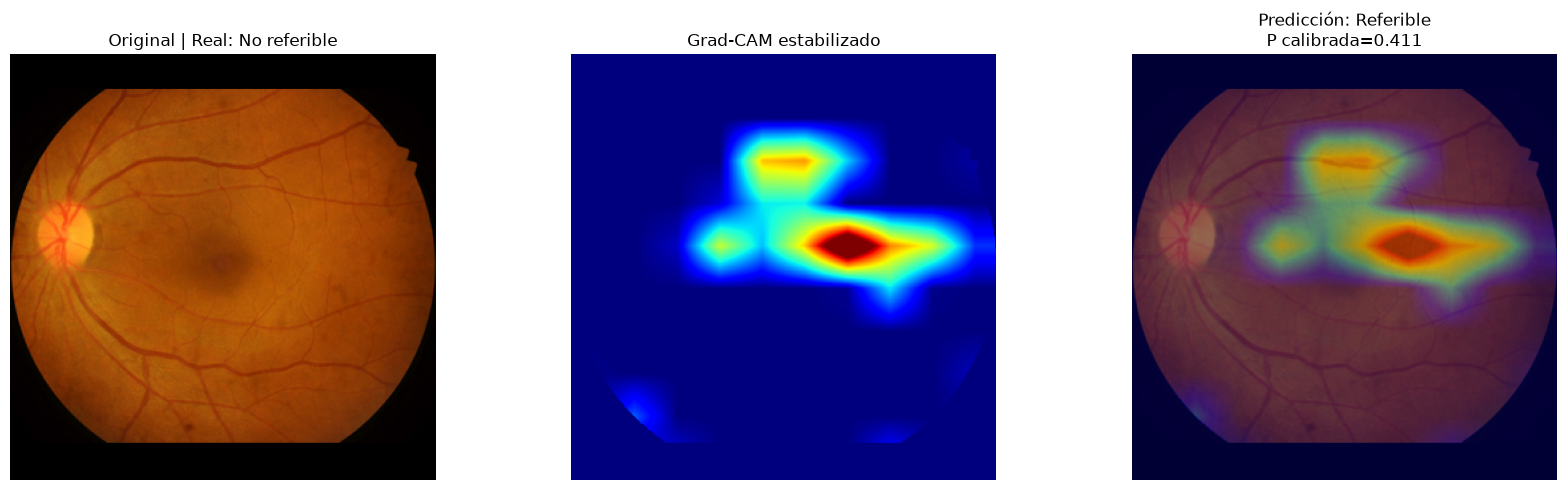

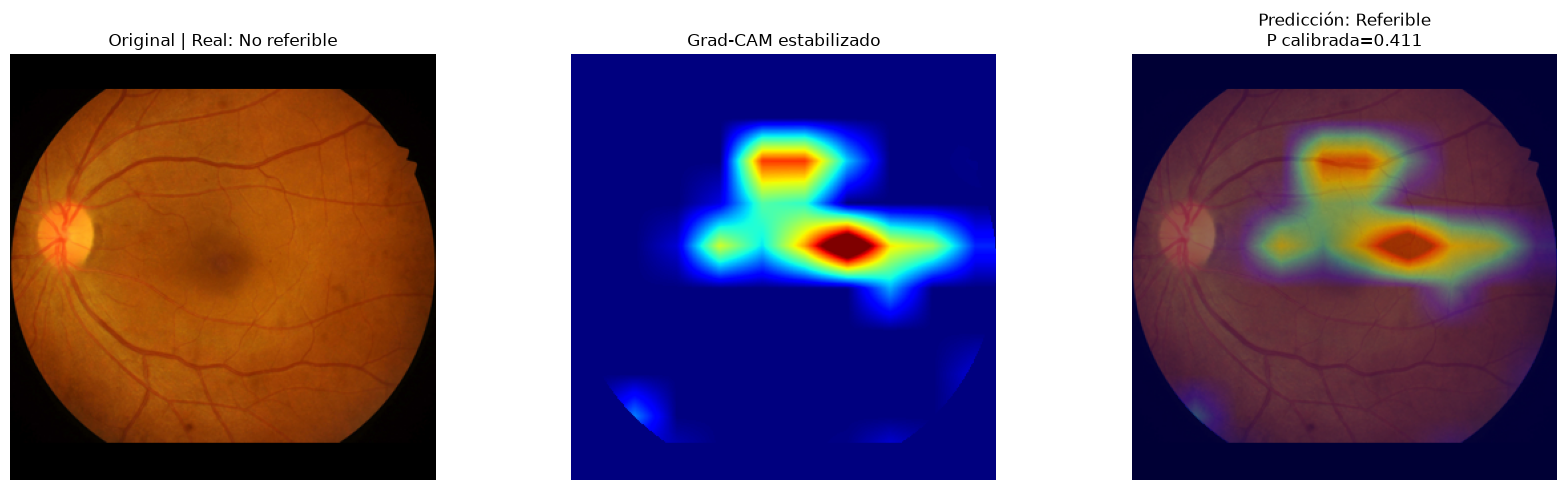

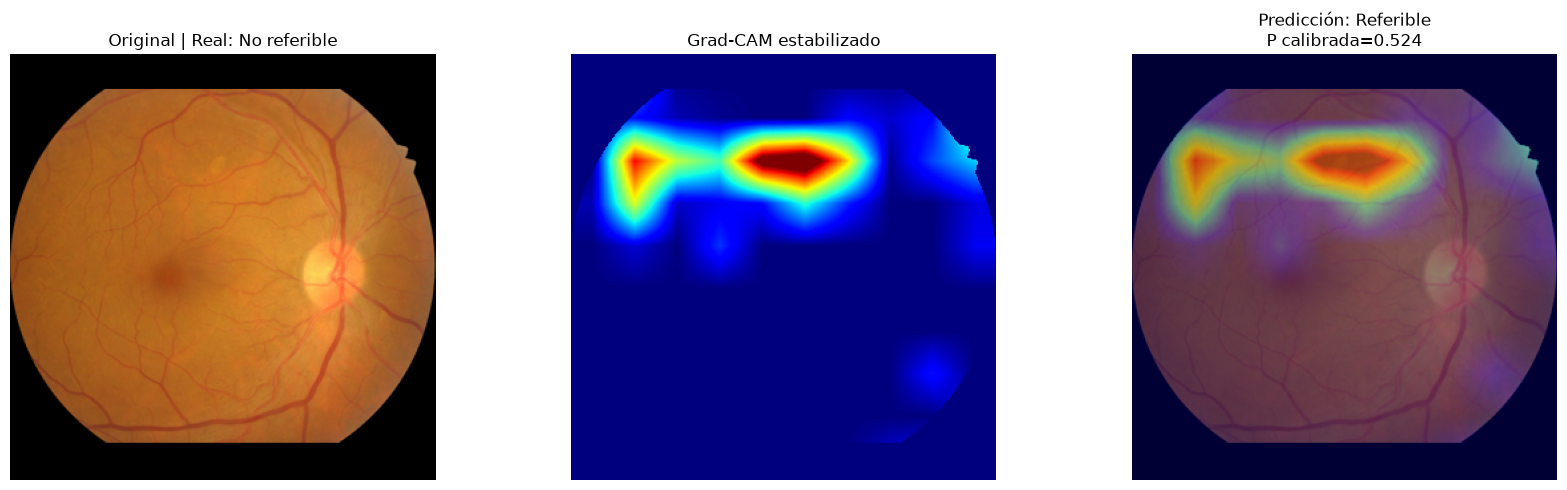

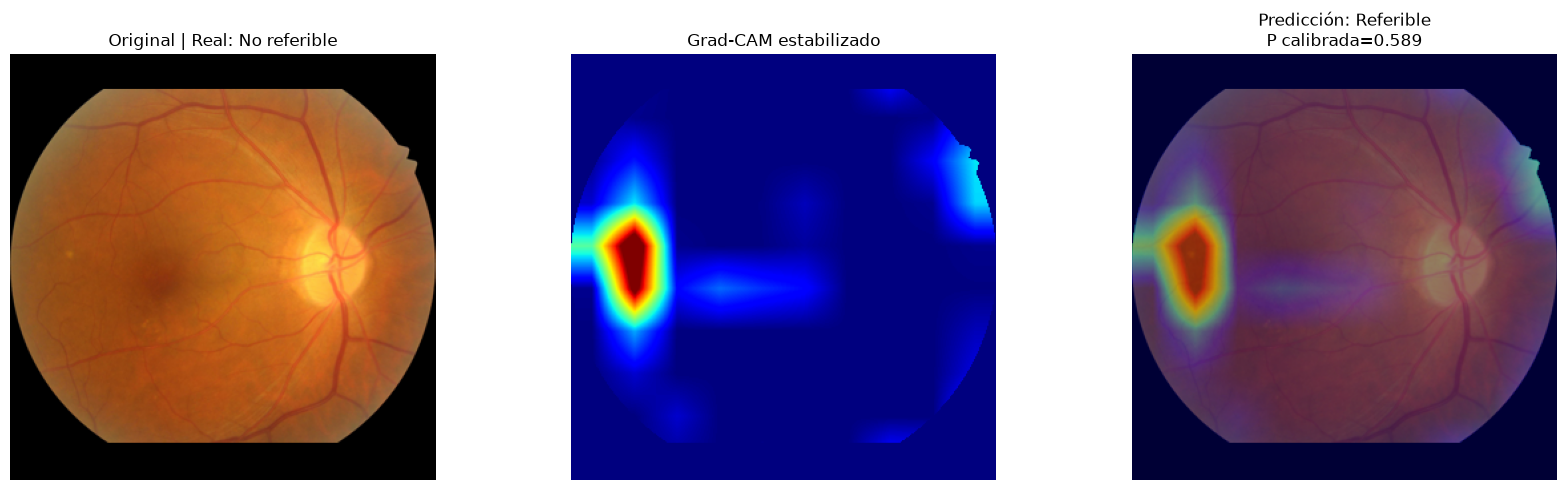

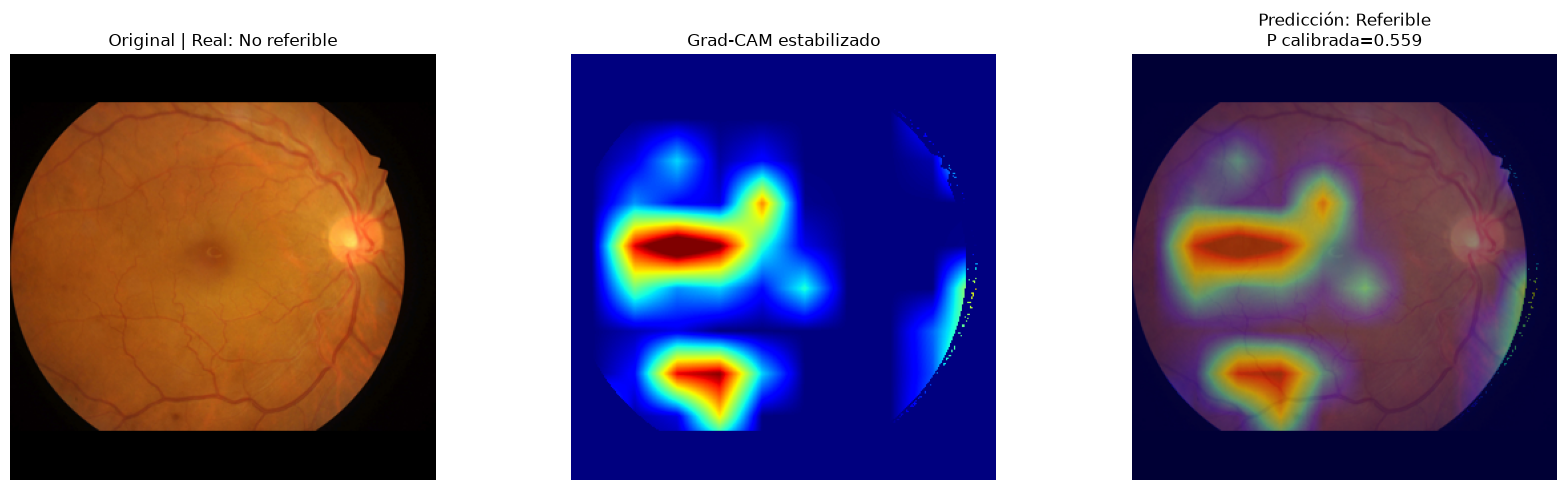

In [67]:
# Mostrar errores clínicamente relevantes: primero falsos negativos y luego falsos positivos.
error_df = test_predictions_df[~test_predictions_df['correct']].copy()
error_df['error_priority'] = np.where(
    (error_df['binary_label'] == 1) & (error_df['predicted_label'] == 0),
    0,
    1,
)
examples = error_df.sort_values(['error_priority', 'calibrated_probability']).head(5)

if examples.empty:
    examples = test_predictions_df.sort_values(
        'calibrated_probability',
        key=lambda series: np.abs(series - CLINICAL_THRESHOLD),
    ).head(3)

for _, row in examples.iterrows():
    result = generate_smooth_gradcam(row['image_path'])
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    axes[0].imshow(result['image'])
    axes[0].set_title(f"Original | Real: {CLASS_NAMES[int(row['binary_label'])]}")
    axes[1].imshow(result['heatmap'], cmap='jet')
    axes[1].set_title('Grad-CAM estabilizado')
    axes[2].imshow(result['overlay'])
    axes[2].set_title(
        f"Predicción: {result['predicted_name']}\n"
        f"P calibrada={result['calibrated_probability']:.3f}"
    )
    for axis in axes:
        axis.axis('off')
    plt.tight_layout()
    plt.show()


## 15. Dashboard clínico interactivo

Resume el aprendizaje y el rendimiento final sin reemplazar el análisis de errores individuales.

In [68]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

DASHBOARD_PATH = RUN_DIR / f'dashboard_{MODEL_NAME}.html'

dashboard = make_subplots(
    rows=2,
    cols=3,
    subplot_titles=[
        'Pérdida',
        'PR AUC',
        'ROC AUC',
        'Matriz de confusión',
        'Curva ROC',
        'Métricas clínicas',
    ],
)

dashboard.add_trace(
    go.Scatter(x=history_df['epoch'], y=history_df['loss'], name='Loss entrenamiento'),
    row=1, col=1,
)
dashboard.add_trace(
    go.Scatter(x=history_df['epoch'], y=history_df['val_loss'], name='Loss ajuste'),
    row=1, col=1,
)
dashboard.add_trace(
    go.Scatter(x=history_df['epoch'], y=history_df['pr_auc'], name='PR AUC entrenamiento'),
    row=1, col=2,
)
dashboard.add_trace(
    go.Scatter(x=history_df['epoch'], y=history_df['val_pr_auc'], name='PR AUC ajuste'),
    row=1, col=2,
)
dashboard.add_trace(
    go.Scatter(x=history_df['epoch'], y=history_df['roc_auc'], name='ROC AUC entrenamiento'),
    row=1, col=3,
)
dashboard.add_trace(
    go.Scatter(x=history_df['epoch'], y=history_df['val_roc_auc'], name='ROC AUC ajuste'),
    row=1, col=3,
)

dashboard.add_trace(
    go.Heatmap(
        z=cm,
        x=[CLASS_NAMES[0], CLASS_NAMES[1]],
        y=[CLASS_NAMES[0], CLASS_NAMES[1]],
        text=cm,
        texttemplate='%{text}',
        showscale=False,
        name='Confusión',
    ),
    row=2, col=1,
)

dashboard.add_trace(
    go.Scatter(x=fpr, y=tpr, name=f"ROC AUC={metrics_test['roc_auc']:.3f}"),
    row=2, col=2,
)
dashboard.add_trace(
    go.Scatter(x=[0, 1], y=[0, 1], line=dict(dash='dash'), name='Aleatorio'),
    row=2, col=2,
)

metric_names = ['Sensibilidad', 'Especificidad', 'PPV', 'NPV', 'Balanced Acc.']
metric_values = [
    metrics_test['sensitivity'],
    metrics_test['specificity'],
    metrics_test['precision_ppv'],
    metrics_test['npv'],
    metrics_test['balanced_accuracy'],
]
dashboard.add_trace(
    go.Bar(
        x=metric_names,
        y=metric_values,
        text=[f'{value:.3f}' for value in metric_values],
        textposition='auto',
        name='Métricas',
    ),
    row=2, col=3,
)

dashboard.update_yaxes(range=[0, 1], row=2, col=3)
dashboard.update_layout(
    title=f'{MODEL_NAME} — evaluación clínica en pacientes originales',
    height=850,
    width=1500,
    template='plotly_white',
    legend=dict(orientation='h', y=-0.15),
)
dashboard.show()
dashboard.write_html(str(DASHBOARD_PATH))
print('Dashboard:', DASHBOARD_PATH)

Dashboard: C:\Users\lauri\Documents\PROYECTO_FINAL\ConvNeXt_Tiny_Clinical\dashboard_ConvNeXt_Tiny_Clinical.html


## 16. Empaquetar resultados

In [69]:
import shutil

archive_path = shutil.make_archive(
    base_name=str(Path('/content') / MODEL_NAME),
    format='zip',
    root_dir=str(RUN_DIR),
)
print('Archivo ZIP:', archive_path)

Archivo ZIP: c:\content\ConvNeXt_Tiny_Clinical.zip
